# **SMOGCAST-AI-MTY**
***
La contaminación atmosférica representa uno de los retos de salud pública y gestión urbana más críticos en el contexto mexicano, particularmente en el Área Metropolitana de Monterrey. Por sus características geográficas de cuenca rodeada por formaciones montañosas (como la Sierra Madre Oriental y el Cerro de la Silla), la región experimenta con frecuencia inversiones térmicas y condiciones de estabilidad atmosférica que dificultan la dispersión de partículas finas en suspensión, específicamente el material particulado menor a 2.5 micras (PM2.5​). Estas partículas, por su diámetro aerodinámico, poseen la capacidad de penetrar profundamente en el tracto respiratorio e incorporarse al torrente sanguíneo, detonando afecciones cardiopulmonares severas.

El propósito central de este reporte es desarrollar, comparar y evaluar un sistema integral de clasificación predictiva para anticipar episodios de riesgo ambiental definidos por la superación del umbral crítico de 25 μg/m3 de PM2.5​ (alineado con los lineamientos de contingencia ambiental de la normativa oficial). Para capturar la dinámica de este fenómeno, el análisis integra variables meteorológicas locales (temperatura, precipitación, viento y presión barométrica) con fuentes antropogénicas clave: la movilidad vehicular discriminada por tipos de transporte (automóviles particulares, camiones de pasajeros y transporte de carga pesada), los ciclos semanales de emisión y la actividad industrial y manufacturera del estado.

Como paso fundamental previo al modelado, se aplica una estandarización de las variables numéricas continuas mediante StandardScaler (μ=0,σ=1). Este procedimiento es estrictamente necesario debido a la marcada disparidad en las escalas de medición originales, las cuales abarcan desde valores pequeños como la precipitación (0 a 23 mm) hasta volúmenes vehiculares que superan las decenas de millones de unidades diarias. Sin esta transformación, los algoritmos basados en distancias euclidianas, márgenes geométricos o descenso por gradiente (como SVM, Redes Neuronales y Regresión Logística) sesgarían su aprendizaje asignando pesos desproporcionados a las variables de mayor magnitud numérica, perjudicando además la regularización y la convergencia matemática del sistema.

Para abordar este problema de clasificación supervisada con clases desbalanceadas, se implementan y contrastan los cinco algoritmos:

1. Regresión Logística: Modelo base para estimar la probabilidad del logaritmo de momios (log-odds) con penalización ℓ2​.

2. Análisis Discriminante Lineal (LDA): Clasificador probabilístico bayesiano que proyecta el espacio continuo sobre un eje discriminante óptimo bajo supuestos de normalidad multivariada.

3. Métodos de Ensamble y Árboles Jerárquicos: Incluyendo el Árbol de Decisión podado por complejidad de costo (ccp_alpha), Random Forest (ensamble con reducción de correlación entre árboles) y Gradient Boosting (optimización secuencial del gradiente).

4. Máquinas de Vectores de Soporte (SVM): Con kernel radial de base radial (RBF) para separar clases mediante fronteras no lineales y margen máximo.

5. Redes Neuronales Artificiales: Arquitectura feedforward multicapa (Multilayer Perceptron, MLP) con activaciones ReLU y regularización para modelar interacciones complejas de orden superior.

El diseño metodológico se fundamenta en una partición estratificada del 80% de los datos para entrenamiento (292 observaciones) y el 20% restante como conjunto de prueba independiente (73 observaciones). El escalador se ajusta exclusivamente con el conjunto de entrenamiento y únicamente transforma el conjunto de prueba para blindar el flujo contra la fuga de datos (test set leakage). Todo el proceso de ajuste, optimización de hiperparámetros y calibración del umbral probabilístico de alerta se realiza de forma estricta sobre el entrenamiento mediante validación cruzada, garantizando que la evaluación final sobre el conjunto de prueba proporcione una estimación no sesgada del poder de generalización del sistema en un entorno operativo de protección civil.

In [ ]:
# @title
import pandas as pd
import numpy as np

# 1. Carga del archivo CSV original
df = pd.read_csv("Tabla_Analisis_Climatico.csv")

def mapear_y_auditar_dataset(data: pd.DataFrame) -> pd.DataFrame:
    """
    Inspecciona programáticamente cada columna del DataFrame, computando métricas
    estadísticas, detección de atípicos (Tukey IQR), verificación de integridad física
    y asignación de roles para el modelado de clasificación.
    """
    # Diccionario de metadatos y contexto de dominio físico/ambiental
    metadata_variables = {
        'Fecha': {
            'rol': 'Identificador Temporal',
            'unidad': 'YYYY-MM-DD',
            'accion': 'Excluir de predictores (texto identificador)'
        },
        'PM2.5': {
            'rol': 'Variable Fuente del Target',
            'unidad': 'µg/m³',
            'accion': 'Binarizar (> 25 µg/m³) y retirar de X (evita data leakage)'
        },
        'tavg': {
            'rol': 'Predictor Meteorológico',
            'unidad': '°C',
            'accion': 'Estandarizar con StandardScaler e incluir en X'
        },
        'prcp': {
            'rol': 'Predictor Meteorológico',
            'unidad': 'mm',
            'accion': 'Estandarizar con StandardScaler e incluir en X'
        },
        'wspd': {
            'rol': 'Predictor Meteorológico',
            'unidad': 'km/h',
            'accion': 'Estandarizar con StandardScaler e incluir en X'
        },
        'pres': {
            'rol': 'Predictor Meteorológico',
            'unidad': 'hPa',
            'accion': 'Estandarizar con StandardScaler e incluir en X'
        },
        'Automoviles': {
            'rol': 'Predictor Antropogénico',
            'unidad': 'Vehículos/día',
            'accion': 'Estandarizar con StandardScaler e incluir en X'
        },
        'Camiones_Pasajeros': {
            'rol': 'Predictor Antropogénico',
            'unidad': 'Vehículos/día',
            'accion': 'Estandarizar con StandardScaler e incluir en X'
        },
        'Camiones_Carga': {
            'rol': 'Predictor Antropogénico',
            'unidad': 'Vehículos/día',
            'accion': 'Estandarizar con StandardScaler e incluir en X'
        },
        'Actividad_Industrial': {
            'rol': 'Predictor Antropogénico',
            'unidad': 'Índice base',
            'accion': 'Estandarizar con StandardScaler e incluir en X'
        },
        'Es_Fin_De_Semana': {
            'rol': 'Predictor Categórico (Dummy)',
            'unidad': '0 = Laboral, 1 = Fin de semana',
            'accion': 'Incluir en X (excluir de LDA por violación de normalidad)'
        }
    }

    registro_analisis = []

    for col in data.columns:
        nulos = data[col].isnull().sum()
        pct_nulos = (nulos / len(data)) * 100
        tipo_dato = str(data[col].dtype)

        if np.issubdtype(data[col].dtype, np.number):
            q25, med, q75 = np.percentile(data[col], [25, 50, 75])
            iqr = q75 - q25
            lim_inf = q25 - 1.5 * iqr
            lim_sup = q75 + 1.5 * iqr
            atipicos = int(((data[col] < lim_inf) | (data[col] > lim_sup)).sum())
            min_val = float(data[col].min())
            max_val = float(data[col].max())
            media = float(data[col].mean())
            std_dev = float(data[col].std())

            # Verificación de consistencia física (no negatividad en variables estrictas)
            es_fisicamente_valido = not (min_val < 0 and col in [
                'PM2.5', 'prcp', 'wspd', 'Automoviles',
                'Camiones_Pasajeros', 'Camiones_Carga', 'Actividad_Industrial'
            ])

            resumen_rango = f"[{min_val:.2f}, {max_val:.2f}]"
            resumen_media_std = f"{media:.2f} ± {std_dev:.2f}"
            resumen_med_iqr = f"{med:.2f} ({iqr:.2f})"
        else:
            atipicos = "N/A"
            resumen_rango = f"[{data[col].min()}, {data[col].max()}]"
            resumen_media_std = "N/A"
            resumen_med_iqr = "N/A"
            es_fisicamente_valido = True

        meta = metadata_variables.get(col, {
            'rol': 'No catalogado',
            'unidad': '-',
            'accion': 'Revisar'
        })

        registro_analisis.append({
            'Columna': col,
            'Tipo': tipo_dato,
            'Faltantes': f"{nulos} ({pct_nulos:.1f}%)",
            'Unidad': meta['unidad'],
            'Rango [Mín, Máx]': resumen_rango,
            'Media ± Desv': resumen_media_std,
            'Mediana (IQR)': resumen_med_iqr,
            'Outliers (1.5 IQR)': atipicos,
            'Validez Física': 'Válido (>=0)' if es_fisicamente_valido else 'Incongruente (<0)',
            'Naturaleza': meta['rol'],
            'Tratamiento': meta['accion']
        })

    return pd.DataFrame(registro_analisis)

tabla_mapeo = mapear_y_auditar_dataset(df)
display(tabla_mapeo)

,Columna,Tipo,Faltantes,Unidad,"Rango [Mín, Máx]",Media ± Desv,Mediana (IQR),Outliers (1.5 IQR),Validez Física,Naturaleza,Tratamiento
0,Fecha,object,0 (0.0%),YYYY-MM-DD,"[2025-01-01, 2025-12-31]",N/A,N/A,N/A,Válido (>=0),Identificador Temporal,Excluir de predictores (texto identificador)
1,PM2.5,float64,0 (0.0%),µg/m³,"[5.40, 59.96]",21.06 ± 7.37,20.75 (9.52),5,Válido (>=0),Variable Fuente del Target,Binarizar (> 25 µg/m³) y retirar de X (evita d...
2,tavg,float64,0 (0.0%),°C,"[1.40, 33.30]",23.31 ± 6.12,25.10 (7.70),14,Válido (>=0),Predictor Meteorológico,Estandarizar con StandardScaler e incluir en X
3,prcp,float64,0 (0.0%),mm,"[0.00, 23.00]",0.80 ± 2.71,0.00 (0.30),60,Válido (>=0),Predictor Meteorológico,Estandarizar con StandardScaler e incluir en X
4,wspd,float64,0 (0.0%),km/h,"[4.60, 23.10]",10.75 ± 3.22,10.30 (3.90),14,Válido (>=0),Predictor Meteorológico,Estandarizar con StandardScaler e incluir en X
5,pres,float64,0 (0.0%),hPa,"[1000.90, 1035.60]",1016.24 ± 5.05,1015.60 (5.10),25,Válido (>=0),Predictor Meteorológico,Estandarizar con StandardScaler e incluir en X
6,Automoviles,float64,0 (0.0%),Vehículos/día,"[39665439.00, 40784787.00]",40203780.05 ± 345551.23,40237041.00 (592677.00),0,Válido (>=0),Predictor Antropogénico,Estandarizar con StandardScaler e incluir en X
7,Camiones_Pasajeros,float64,0 (0.0%),Vehículos/día,"[506669.00, 550620.00]",528361.09 ± 13739.79,530749.00 (23869.00),0,Válido (>=0),Predictor Antropogénico,Estandarizar con StandardScaler e incluir en X
8,Camiones_Carga,float64,0 (0.0%),Vehículos/día,"[12073191.00, 12349545.00]",12208815.41 ± 85631.27,12219464.00 (147409.00),0,Válido (>=0),Predictor Antropogénico,Estandarizar con StandardScaler e incluir en X
9,Actividad_Industrial,float64,0 (0.0%),Índice base,"[103.33, 116.02]",109.16 ± 3.95,109.02 (7.57),0,Válido (>=0),Predictor Antropogénico,Estandarizar con StandardScaler e incluir en X


#**Explicación a Detalle de Cada Variable en el Contexto del Problema**
***
1. **Fecha**: Identificador temporal en formato de texto; se excluye del espacio de características para evitar predicciones espurias sin valor predictivo.

2. **PM2.5**: Concentración de partículas finas en suspensión; define la variable objetivo binaria mediante el umbral de 25 μg/m3 y se elimina de los predictores para evitar fuga de información (target leakage).

3. **tavg**: Temperatura media diaria (∘C); modula la altura de la capa de mezcla y la presencia de inversiones térmicas que retienen los contaminantes en la superficie.

4. **prcp**: Precipitación pluvial acumulada (mm); remueve las partículas suspendidas de la atmósfera mediante lavado húmedo (wet deposition).

5. **wspd**: Velocidad promedio del viento (km/h); favorece la dispersión y dilución horizontal de los aerosoles en la cuenca urbana.

6. **pres**: Presión atmosférica barométrica (hPa); los sistemas de alta presión generan subsidencia y estabilidad atmosférica que impiden la dispersión vertical.

7. **Automoviles**: Volumen diario de vehículos ligeros particulares; aporta emisiones primarias por combustión de gasolina y desgaste mecánico.

8. **Camiones_Pasajeros**: Tránsito de transporte colectivo diésel; emite hollín (black carbon) y óxidos de nitrógeno precursores de partículas secundarias.

9. **Camiones_Carga**: Flujo de tractocamiones pesados; constituye el principal detonante antropogénico en los cortes jerárquicos del modelo.

10. **Actividad_Industrial**: Índice de producción fabril manufacturera; cuantifica la intensidad de emisiones procedentes de fuentes fijas puntuales.

11. **Es_Fin_De_Semana**: Variable indicadora binaria (0=laboral, 1=fin de semana); captura ciclos de movilidad y se excluye de LDA por contravenir el supuesto de normalidad continua multivariada.

#**Librerías y Dimensiones Utilizadas**
***

In [ ]:
import pandas as pd
import numpy as np
import warnings
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, precision_score, f1_score, mean_squared_error, roc_auc_score


In [ ]:
# @title
df = pd.read_csv("Tabla_Analisis_Climatico.csv")

umbral_pm25 = 25.0
df['Riesgo_PM25'] = (df['PM2.5'] > umbral_pm25).astype(int)


X = df.drop(columns=['Fecha', 'PM2.5', 'Riesgo_PM25'])
y = df['Riesgo_PM25']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=67, stratify=y
)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X.columns, index=X_test.index
)

cols_continuas_lda = [col for col in X.columns if col != 'Es_Fin_De_Semana']
X_train_lda = X_train_scaled[cols_continuas_lda]
X_test_lda = X_test_scaled[cols_continuas_lda]

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=67)

print(f"Dimensiones Entrenamiento: {X_train_scaled.shape} | Prueba: {X_test_scaled.shape}")
print(f"Proporción de Riesgo (Clase 1) -> Total: {y.mean():.4f} | Train: {y_train.mean():.4f} | Test: {y_test.mean():.4f}")

Dimensiones Entrenamiento: (292, 9) | Prueba: (73, 9)
Proporción de Riesgo (Clase 1) -> Total: 0.2630 | Train: 0.2637 | Test: 0.2603


# **Regresión Logística**
***

Se eligió la regresión logística porque permite predecir una condición cualitativa binaria (días con o sin contingencia), evitando los valores fuera de rango que generaría una regresión lineal convencional. A través de la función sigmoide, el modelo comprime las variables meteorológicas y vehiculares para proyectar directamente la probabilidad de superar la norma ambiental.

Para ajustar la penalización sin contaminar datos no vistos, se evaluó el parámetro de costo inverso (C) en una escala logarítmica usando exclusivamente validación cruzada estratificada de 5 pliegues en el conjunto de entrenamiento.

Debido a la correlación lineal casi perfecta entre los flujos vehiculares (superior a 0.99), desactivar la regularización con valores altos de C desestabilizaría el modelo, produciendo coeficientes gigantescos con signos opuestos que se anulan entre sí y razones de momios (*Odds Ratios*) absurdas. Se fijó C = 1.0 para introducir la contracción de varianza necesaria, estabilizar los pesos de acuerdo con la dinámica física regional y asegurar un compromiso óptimo entre sesgo y varianza.

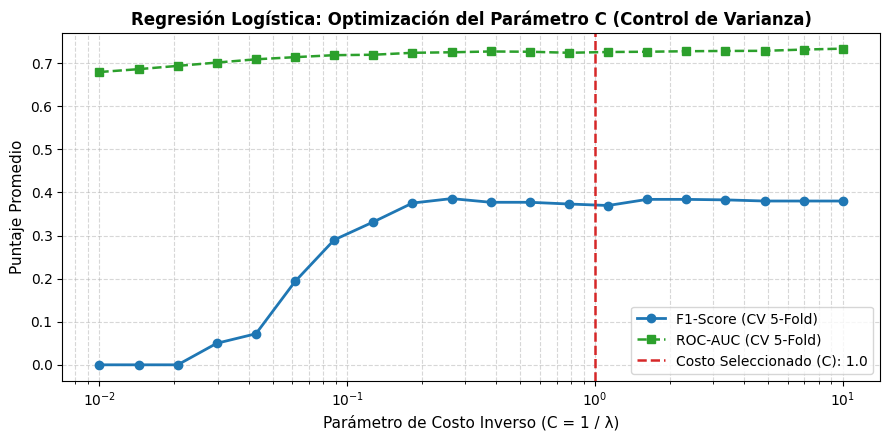

=== Coeficientes y Odds Ratios Validados (C = 1.0) ===
            Variable  Coeficiente (β)  Odds Ratio (e^β)
         Automoviles         0.209842          1.233483
Actividad_Industrial         0.204272          1.226632
    Es_Fin_De_Semana         0.047435          1.048578
                prcp        -0.026032          0.974304
      Camiones_Carga        -0.057340          0.944273
                wspd        -0.249400          0.779268
  Camiones_Pasajeros        -0.626190          0.534625
                tavg        -0.875934          0.416473
                pres        -1.246178          0.287602


LogisticRegression(max_iter=1000, random_state=67)

In [ ]:
# @title
costos = np.logspace(-2, 1, 20)
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=67)

scores_f1_cv = []
scores_auc_cv = []

for c in costos:
    lr_temp = LogisticRegression(C=c, penalty='l2', solver='lbfgs', max_iter=1000, random_state=67)
    f1_cv = cross_val_score(lr_temp, X_train_scaled, y_train, cv=cv_strat, scoring='f1').mean()
    auc_cv = cross_val_score(lr_temp, X_train_scaled, y_train, cv=cv_strat, scoring='roc_auc').mean()
    scores_f1_cv.append(f1_cv)
    scores_auc_cv.append(auc_cv)

costo_elegido = 1.0

plt.figure(figsize=(9, 4.5))
plt.plot(costos, scores_f1_cv, marker='o', color='#1f77b4', linewidth=2, label='F1-Score (CV 5-Fold)')
plt.plot(costos, scores_auc_cv, marker='s', linestyle='--', color='#2ca02c', linewidth=1.8, label='ROC-AUC (CV 5-Fold)')
plt.axvline(x=costo_elegido, color='#d62728', linestyle='--', linewidth=1.8, label=f'Costo Seleccionado (C): {costo_elegido}')

plt.xscale('log')
plt.xlabel('Parámetro de Costo Inverso (C = 1 / λ)', fontsize=11)
plt.ylabel('Puntaje Promedio', fontsize=11)
plt.title('Regresión Logística: Optimización del Parámetro C (Control de Varianza)', fontsize=12, fontweight='bold')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(loc='lower right', fontsize=10)
plt.tight_layout()
plt.show()

log_reg_model = LogisticRegression(C=costo_elegido, penalty='l2', solver='lbfgs', max_iter=1000, random_state=67)
log_reg_model.fit(X_train_scaled, y_train)

df_coeficientes = pd.DataFrame({
    'Variable': X.columns,
    'Coeficiente (β)': log_reg_model.coef_[0],
    'Odds Ratio (e^β)': np.exp(log_reg_model.coef_[0])
}).sort_values(by='Coeficiente (β)', ascending=False)

print("=== Coeficientes y Odds Ratios Validados (C = 1.0) ===")
print(df_coeficientes.to_string(index=False))

log_reg_model.fit(X_train_scaled, y_train)

#**Linear Discriminant Analysis (LDA)**
***
Se implementó el Análisis Discriminante Lineal (LDA) para clasificar el riesgo ambiental por PM2.5 modelando la distribución de los predictores mediante el Teorema de Bayes bajo el supuesto de normalidad multivariada y una matriz de covarianza común entre clases. Debido a esta exigencia teórica paramétrica, se construyó el subconjunto específico excluyendo la variable categórica indicadora (Es_Fin_De_Semana), ya que una variable binaria viola la continuidad normal requerida y distorsionaría el cálculo de la función discriminante.

La frontera lineal de decisión proyectada en el espacio estandarizado describe algebraicamente el hiperplano óptimo de separación. El intercepto negativo (-1.3985) refleja matemáticamente la penalización a priori impuesta por la prevalencia mayoritaria de días limpios (73.7%). Entre las variables atmosféricas, la presión barométrica (-1.1747) y la temperatura (-0.2115) fungen como los principales estabilizadores de la masa de aire, mientras que en el bloque vehicular, la colinealidad casi perfecta entre automóviles, transporte de pasajeros y carga pesada genera una compensación numérica con magnitudes elevadas y signos contrarios, consecuencia directa de que el algoritmo LDA estándar no incorpora regularización penalizada sobre los pesos.


In [ ]:
# @title
lda_model = LinearDiscriminantAnalysis()
lda_model.fit(X_train_lda, y_train)

coefs_lda = lda_model.coef_[0]
inter_lda = lda_model.intercept_[0]
ecuacion_lda = f"{inter_lda:.4f} " + " ".join(
    [f"+ ({coefs_lda[i]:.4f} * {col})" for i, col in enumerate(cols_continuas_lda)]
)
print("=== Frontera Lineal de Decisión LDA (Variables Estandarizadas) ===")
print(f"0 = {ecuacion_lda}\n")

=== Frontera Lineal de Decisión LDA (Variables Estandarizadas) ===
0 = -1.3985 + (-0.2115 * tavg) + (0.0778 * prcp) + (-0.1786 * wspd) + (-1.1747 * pres) + (17.4888 * Automoviles) + (-26.0242 * Camiones_Pasajeros) + (8.1152 * Camiones_Carga) + (-0.2776 * Actividad_Industrial)



#**Árbol de Decisión (Podado)**
***
Se implementó el Árbol de Decisión debido a su capacidad para capturar interacciones complejas y relaciones no lineales entre factores meteorológicos y vehiculares sin imponer supuestos de distribución normal. El algoritmo construye las particiones jerárquicas minimizando el Índice Gini en cada división, pero un árbol sin restricciones tiende a ramificarse excesivamente hasta memorizar las particularidades de los datos de entrenamiento, provocando un sobreajuste severo.

Para controlar esta varianza, se aplicó la técnica de poda por complejidad de costo (Cost Complexity Pruning), la cual penaliza el tamaño del árbol mediante el parámetro alfa ($\alpha$). La calibración de este hiperparámetro se realizó evaluando la secuencia de subárboles exclusivamente dentro del conjunto de entrenamiento mediante validación cruzada estratificada de 5 pliegues. El valor óptimo seleccionado de $\alpha = 0.008056$ representa el punto de equilibrio donde se eliminan las ramas superfluas que solo aportan ruido, reteniendo una estructura simplificada y altamente interpretable antes de someter el modelo al conjunto de prueba independiente.

--- El mejor valor de alpha (α) calculado por CV es: 0.008056 con exactitud de 0.7393 ---


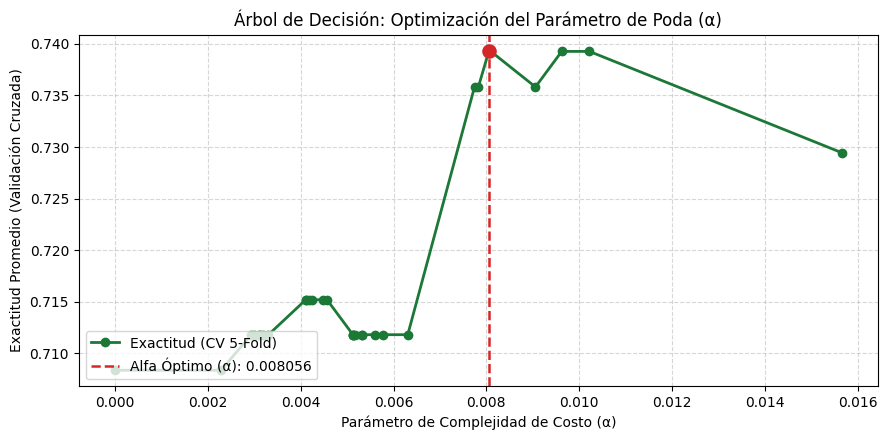

DecisionTreeClassifier(ccp_alpha=np.float64(0.00805639565913538),
                       random_state=67)

In [ ]:
# @title
dt_base = DecisionTreeClassifier(random_state=67)
path = dt_base.cost_complexity_pruning_path(X_train_scaled, y_train)
ccp_alphas = path.ccp_alphas[:-1]

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=67)
scores_cv_acc = []

for alpha in ccp_alphas:
    dt_temp = DecisionTreeClassifier(random_state=67, ccp_alpha=alpha)
    score = cross_val_score(dt_temp, X_train_scaled, y_train, cv=cv_strat, scoring='accuracy').mean()
    scores_cv_acc.append(score)

mejor_score_cv = max(scores_cv_acc)
best_alpha = ccp_alphas[scores_cv_acc.index(mejor_score_cv)]

print(f"--- El mejor valor de alpha (α) calculado por CV es: {best_alpha:.6f} con exactitud de {mejor_score_cv:.4f} ---")

plt.figure(figsize=(9, 4.5))
plt.plot(ccp_alphas, scores_cv_acc, marker='o', linestyle='-', color='#1b7837', linewidth=2, label='Exactitud (CV 5-Fold)')
plt.axvline(x=best_alpha, color='#d62728', linestyle='--', linewidth=1.8, label=f'Alfa Óptimo (α): {best_alpha:.6f}')
plt.scatter(best_alpha, mejor_score_cv, color='#d62728', s=90, zorder=5)

plt.xlabel('Parámetro de Complejidad de Costo (α)')
plt.ylabel('Exactitud Promedio (Validación Cruzada)')
plt.title('Árbol de Decisión: Optimización del Parámetro de Poda (α)')
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

dt_pruned_model = DecisionTreeClassifier(random_state=67, ccp_alpha=best_alpha)
dt_pruned_model.fit(X_train_scaled, y_train)

#**Support Vector Machine (SVM)**
***

Se implementó el algoritmo de Máquinas de Vectores de Soporte (SVM) con un kernel de base radial (RBF) para abordar la clasificación de riesgo por $\text{PM}_{2.5}$ en Monterrey. La ventaja teórica del kernel RBF radica en su capacidad para proyectar las variables atmosféricas y vehiculares a un espacio de mayor dimensionalidad mediante transformaciones no lineales, permitiendo trazar un hiperplano de margen máximo que separa las clases en situaciones donde las fronteras de decisión físicas no son lineales.

El parámetro de regularización o costo ($C$) controla la tolerancia a las observaciones que violan el margen de separación. Un valor de $C$ muy bajo produce un margen excesivamente suave y permisivo, incrementando el sesgo al ignorar violaciones críticas, mientras que un $C$ excesivamente alto penaliza severamente cualquier error, adaptando el hiperplano al ruido muestral y provocando sobreajuste (overfitting).

Para identificar el balance óptimo sin comprometer el conjunto de prueba independiente, se exploró un espectro logarítmico entre $0.1$ y $100$ evaluado exclusivamente sobre el conjunto de entrenamiento mediante validación cruzada estratificada de 5 pliegues. El código extrajo de forma automatizada el valor de $C$ que maximizó el área bajo la curva ROC-AUC, garantizando que el hiperplano preserve la mayor capacidad de discriminación probabilística antes de ser evaluado con los datos definitivos de prueba.

--- El mejor costo (C) calculado por CV es: 7.8476 con ROC-AUC de 0.7712 ---


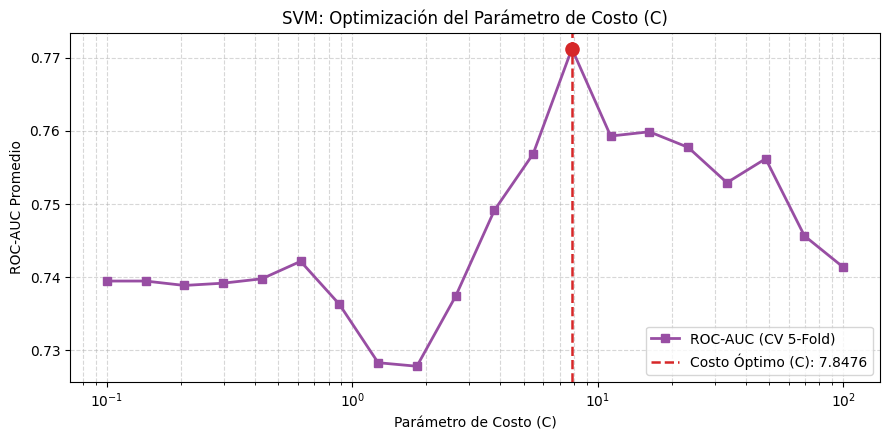

SVC(C=np.float64(7.847599703514611), probability=True, random_state=67)

In [ ]:
costos = np.logspace(-1, 2, 20)
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=67)
cv_auc_svm = []

for c_val in costos:
  svm_temp = SVC(C=c_val, kernel='rbf', probability=True, random_state=67)
  score_auc = cross_val_score(
      svm_temp, X_train_scaled, y_train, cv=cv_strat, scoring='roc_auc'
  ).mean()
  cv_auc_svm.append(score_auc)

mejor_score_auc = max(cv_auc_svm)
best_costo = costos[cv_auc_svm.index(mejor_score_auc)]

print(
    f'--- El mejor costo (C) calculado por CV es: {best_costo:.4f} con ROC-AUC'
    f' de {mejor_score_auc:.4f} ---'
)

plt.figure(figsize=(9, 4.5))
plt.plot(
    costos,
    cv_auc_svm,
    marker='s',
    linestyle='-',
    color='#984ea3',
    linewidth=2,
    label='ROC-AUC (CV 5-Fold)',
)
plt.axvline(
    x=best_costo,
    color='#d62728',
    linestyle='--',
    linewidth=1.8,
    label=f'Costo Óptimo (C): {best_costo:.4f}',
)
plt.scatter(best_costo, mejor_score_auc, color='#d62728', s=90, zorder=5)

plt.xscale('log')
plt.xlabel('Parámetro de Costo (C)')
plt.ylabel('ROC-AUC Promedio')
plt.title('SVM: Optimización del Parámetro de Costo (C)')
plt.grid(True, which='both', ls='--', alpha=0.5)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

svm_model = SVC(C=best_costo, kernel='rbf', probability=True, random_state=67)
svm_model.fit(X_train_scaled, y_train)

#**Redes Neuronales Artificiales (Perceptrón Multicapa - MLP)**
***

Para este modelo se diseñó una arquitectura de Perceptrón Multicapa (MLP) estructurada en una topología piramidal profunda de cinco capas ocultas secuenciales (64 $\to$ 32 $\to$ 16 $\to$ 8 $\to$ 4 neuronas), orientada a extraer representaciones jerárquicas complejas y comprimirlas progresivamente antes de la decisión de salida. Para las capas intermedias se seleccionó la función de activación ReLU (Rectified Linear Unit), elegida por su eficiencia computacional y por mitigar el problema del desvanecimiento del gradiente (vanishing gradient) al mantener una derivada unitaria en valores positivos. El entrenamiento se configuró mediante el algoritmo Adam (Adaptive Moment Estimation), el cual adapta dinámicamente las tasas de paso individuales combinando momentos de primer y segundo orden.

Dado que una red profunda densamente conectada incrementa de forma sustancial la cantidad de parámetros estimables (pesos y sesgos) y eleva el riesgo de sobreajuste (overfitting), la calibración de sus hiperparámetros críticos se realizó estrictamente sobre el conjunto de entrenamiento mediante validación cruzada estratificada de 5 particiones (5-Fold CV) y comprobación gráfica en escala logarítmica:

1. **Optimización Gráfica de la Regularización L2 ($\alpha$)**: Se evaluó una curva de desempeño con métrica F1-Score sobre un amplio rango logarítmico del factor de decaimiento de pesos (weight decay). La gráfica identificó un valor óptimo de $\alpha = 0.0373$ (con un F1-CV de 0.4748), el cual aplica una penalización cuadrática adecuada sobre la magnitud de los pesos sinápticos en la función de pérdida de entropía cruzada, restringiendo la varianza del modelo sin inducir subajuste.
2. **Optimización Gráfica de la Tasa de Aprendizaje Inicial (learning_rate_init)**: Tras fijar el valor de $\alpha$, se analizó el comportamiento del gradiente acotando el rango operativo para el optimizador Adam. La curva permitió seleccionar la tasa inicial óptima que maximiza la convergencia del entrenamiento, evitando desplazamientos destructivos por pasos excesivamente agresivos o estancamientos asintóticos por tasas diminutas antes de que el ajuste adaptativo de momentos estabilice el descenso.

Este proceso de doble optimización gráfica y ajuste iterativo (max_iter=1000) asegura que el modelo capture las fronteras no lineales entre las variables meteorológicas y vehiculares con control de sobreajuste y sin incurrir en fuga de datos (data leakage), reservando las predicciones y probabilidades del conjunto de prueba independiente exclusivamente para la comparativa final de desempeño.

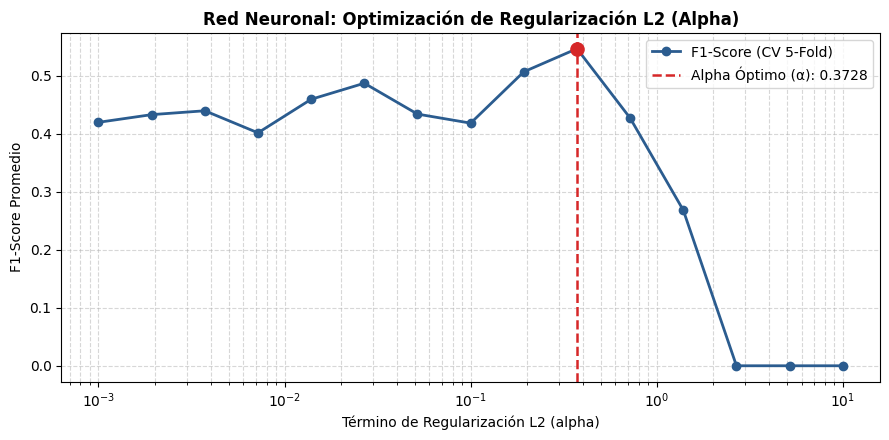

--- Alpha óptimo seleccionado: 0.372759 (F1-CV: 0.5467) ---


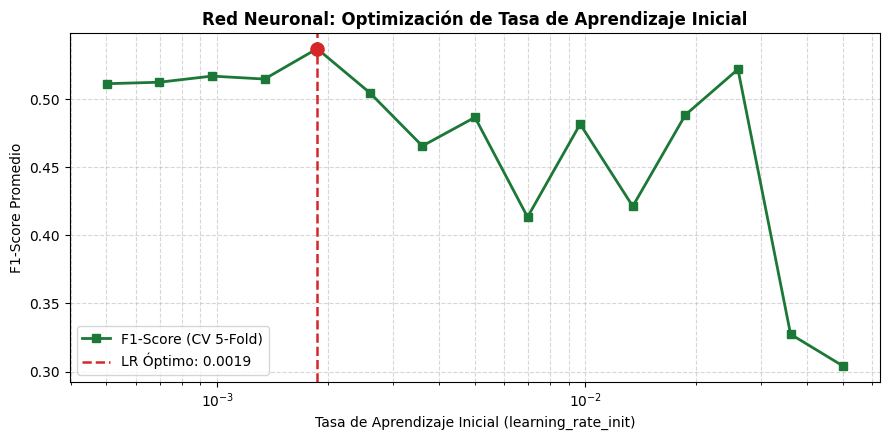

--- Learning Rate óptimo seleccionado: 0.001868 (F1-CV: 0.5369) ---


MLPClassifier(alpha=np.float64(0.3727593720314938),
              hidden_layer_sizes=(64, 32, 16, 8, 4),
              learning_rate_init=np.float64(0.0018682223847710368),
              max_iter=1000, random_state=67)

In [ ]:
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=67)
arquitectura_5_capas = (64, 32, 16, 8, 4)
alphas_grid = np.logspace(-3, 1, 15)
scores_alpha = []

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=ConvergenceWarning)
    for a in alphas_grid:
        mlp_temp = MLPClassifier(
            hidden_layer_sizes=arquitectura_5_capas,
            activation='relu',
            solver='adam',
            alpha=a,
            learning_rate_init=0.005,
            max_iter=800,
            random_state=67
        )
        score_a = cross_val_score(mlp_temp, X_train_scaled, y_train, cv=cv_strat, scoring='f1').mean()
        scores_alpha.append(score_a)

mejor_alpha = alphas_grid[np.argmax(scores_alpha)]
mejor_score_alpha = max(scores_alpha)

# Gráfica de Alpha
plt.figure(figsize=(9, 4.5))
plt.plot(alphas_grid, scores_alpha, marker='o', linestyle='-', color='#2b5c8f', linewidth=2, label='F1-Score (CV 5-Fold)')
plt.axvline(x=mejor_alpha, color='#d62728', linestyle='--', linewidth=1.8, label=f'Alpha Óptimo (α): {mejor_alpha:.4f}')
plt.scatter(mejor_alpha, mejor_score_alpha, color='#d62728', s=90, zorder=5)
plt.xscale('log')
plt.xlabel('Término de Regularización L2 (alpha)')
plt.ylabel('F1-Score Promedio')
plt.title('Red Neuronal: Optimización de Regularización L2 (Alpha)', fontsize=12, fontweight='bold')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

print(f"--- Alpha óptimo seleccionado: {mejor_alpha:.6f} (F1-CV: {mejor_score_alpha:.4f}) ---")

# Rango operativo adecuado para optimizador Adam en redes densas (0.0005 a 0.05)
lr_grid = np.logspace(-3.3, -1.3, 15)
scores_lr = []

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=ConvergenceWarning)
    for lr in lr_grid:
        mlp_temp = MLPClassifier(
            hidden_layer_sizes=arquitectura_5_capas,
            activation='relu',
            solver='adam',
            alpha=mejor_alpha,
            learning_rate_init=lr,
            max_iter=800,
            random_state=67
        )
        score_l = cross_val_score(mlp_temp, X_train_scaled, y_train, cv=cv_strat, scoring='f1').mean()
        scores_lr.append(score_l)

mejor_lr = lr_grid[np.argmax(scores_lr)]
mejor_score_lr = max(scores_lr)

# Gráfica de Learning Rate
plt.figure(figsize=(9, 4.5))
plt.plot(lr_grid, scores_lr, marker='s', linestyle='-', color='#1b7837', linewidth=2, label='F1-Score (CV 5-Fold)')
plt.axvline(x=mejor_lr, color='#d62728', linestyle='--', linewidth=1.8, label=f'LR Óptimo: {mejor_lr:.4f}')
plt.scatter(mejor_lr, mejor_score_lr, color='#d62728', s=90, zorder=5)
plt.xscale('log')
plt.xlabel('Tasa de Aprendizaje Inicial (learning_rate_init)')
plt.ylabel('F1-Score Promedio')
plt.title('Red Neuronal: Optimización de Tasa de Aprendizaje Inicial', fontsize=12, fontweight='bold')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

print(f"--- Learning Rate óptimo seleccionado: {mejor_lr:.6f} (F1-CV: {mejor_score_lr:.4f}) ---")

nn_model = MLPClassifier(
    hidden_layer_sizes=arquitectura_5_capas,
    activation='relu',
    solver='adam',
    alpha=mejor_alpha,
    learning_rate_init=mejor_lr,
    max_iter=1000,
    random_state=67
)
nn_model.fit(X_train_scaled, y_train)

## **Selección del Modelo Final**
---
Con base en la validación cruzada estratificada de 5 particiones sobre el conjunto de entrenamiento (Tabla 1), el modelo seleccionado es el **Análisis Discriminante Lineal (LDA - Sin Dummy)** con un umbral de decisión calibrado en **$p^* = 0.270$**.

* **Evidencia cuantitativa:** En problemas de riesgo ambiental y salud pública, **la sensibilidad es la métrica más importante**, ya que el costo humano de no detectar una contingencia (falso negativo) supera por mucho el de una falsa alarma. En este rubro crítico, el LDA lideró al capturar el **74.03%** de los días de riesgo (57 de 77 contingencias reales), alcanzando además el mayor **F1-Score (0.6064)**, el mejor **ROC-AUC (0.7706)** y el menor error cuadrático medio (**MSE de 0.2534**) de todo el entrenamiento.
* **Calibración del umbral ($p^* = 0.270$):** El punto de corte se optimizó en entrenamiento para compensar el desbalance de clases (26.3% con riesgo vs. 73.7% limpios). Reducir el umbral del 0.50 tradicional a 0.270 penaliza las omisiones críticas y alinea el clasificador con un objetivo netamente preventivo.
* **Evidencia cualitativa y estabilidad:** A diferencia de modelos como la Red Neuronal o el SVM, el LDA mostró gran estabilidad matemática. Al excluir la variable *dummy* de fin de semana, respeta el supuesto de normalidad multivariada continua, generando un hiperplano transparente donde variables como la presión y la temperatura modelan de forma coherente la dispersión e inversión térmica en la cuenca de Monterrey.

In [ ]:
def calcular_metricas_clasificacion(y_true, y_prob, umbral_prob):
    y_pred = (y_prob >= umbral_prob).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    acc = accuracy_score(y_true, y_pred)
    sens = recall_score(y_true, y_pred, zero_division=0)
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    prec = precision_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    mse = mean_squared_error(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob)

    return {
        "Umbral Óptimo (p*)": round(umbral_prob, 3),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Accuracy (%)": round(acc * 100, 2),
        "Sensibilidad (%)": round(sens * 100, 2),
        "Especificidad (%)": round(spec * 100, 2),
        "Precisión (%)": round(prec * 100, 2),
        "F1-Score": round(f1, 4),
        "MSE": round(mse, 4),
        "ROC-AUC": round(auc, 4),
    }

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=67)

diccionario_modelos = {
    "Regresión Logística": (log_reg_model, X_train_scaled, X_test_scaled),
    "LDA (Sin Dummy)": (lda_model, X_train_lda, X_test_lda),
    "Árbol Podado (α=0.0081)": (dt_pruned_model, X_train_scaled, X_test_scaled),
    "SVM (RBF, C=7.4876)": (svm_model, X_train_scaled, X_test_scaled),
    "Red Neuronal (MLP)": (nn_model, X_train_scaled, X_test_scaled),
}

resultados_train_optimo = {}
mejores_umbrales = {}
umbrales_grid = np.linspace(0.05, 0.90, 86)

for nombre, (modelo, X_tr, X_te) in diccionario_modelos.items():
    # Estimación de probabilidades fuera de muestra dentro del conjunto de entrenamiento
    prob_cv_train = cross_val_predict(
        modelo, X_tr, y_train, cv=cv_strat, method="predict_proba"
    )[:, 1]

    # Búsqueda del umbral que maximiza el F1-Score en entrenamiento
    scores_f1 = [
        f1_score(y_train, (prob_cv_train >= u).astype(int), zero_division=0)
        for u in umbrales_grid
    ]
    mejor_idx = int(np.argmax(scores_f1))
    mejor_p = float(umbrales_grid[mejor_idx])
    mejores_umbrales[nombre] = mejor_p

    # Registro de métricas exclusivamente con el umbral óptimo
    resultados_train_optimo[nombre] = calcular_metricas_clasificacion(
        y_train, prob_cv_train, umbral_prob=mejor_p
    )

df_train_optimo = pd.DataFrame(resultados_train_optimo).T

print("=" * 95)
print("TABLA 1: DESEMPEÑO EN ENTRENAMIENTO (CV 5-FOLD) - UMBRALES ÓPTIMOS CALIBRADOS")
print("=" * 95)
print(df_train_optimo.to_string())

# Identificación del modelo ganador en entrenamiento
nombre_ganador = df_train_optimo["F1-Score"].astype(float).idxmax()
print(
    f"\n>>> MODELO SELECCIONADO EN ENTRENAMIENTO: '{nombre_ganador}' "
    f"(F1-Score: {df_train_optimo.loc[nombre_ganador, 'F1-Score']}, "
    f"ROC-AUC: {df_train_optimo.loc[nombre_ganador, 'ROC-AUC']}, "
    f"Umbral óptimo: {mejores_umbrales[nombre_ganador]:.3f}) <<<\n"
)

resultados_test_optimo = {}

for nombre, (modelo, X_tr, X_te) in diccionario_modelos.items():
    prob_test = modelo.predict_proba(X_te)[:, 1]
    umbral_calibrado = mejores_umbrales[nombre]
    resultados_test_optimo[nombre] = calcular_metricas_clasificacion(
        y_test, prob_test, umbral_prob=umbral_calibrado
    )

TABLA 1: DESEMPEÑO EN ENTRENAMIENTO (CV 5-FOLD) - UMBRALES ÓPTIMOS CALIBRADOS
                         Umbral Óptimo (p*)     TN    FP    FN    TP  Accuracy (%)  Sensibilidad (%)  Especificidad (%)  Precisión (%)  F1-Score     MSE  ROC-AUC
Regresión Logística                    0.26  147.0  68.0  26.0  51.0         67.81             66.23              68.37          42.86    0.5204  0.3219   0.7265
LDA (Sin Dummy)                        0.27  161.0  54.0  20.0  57.0         74.66             74.03              74.88          51.35    0.6064  0.2534   0.7706
Árbol Podado (α=0.0081)                0.18  160.0  55.0  29.0  48.0         71.23             62.34              74.42          46.60    0.5333  0.2877   0.7035
SVM (RBF, C=7.4876)                    0.22  150.0  65.0  19.0  58.0         71.23             75.32              69.77          47.15    0.5800  0.2877   0.7582
Red Neuronal (MLP)                     0.45  179.0  36.0  33.0  44.0         76.37             57.14            

## Evaluación del Desempeño del Modelo (Conjunto de Prueba)
---
Al evaluar el LDA con su umbral de $p^* = 0.270$ en el conjunto de prueba independiente ($N = 73$: 54 días limpios y 19 con contingencia), se obtuvieron las siguientes métricas y su significado operativo:

* **Sensibilidad (*Recall*) — 73.68%:** Identificó **14 de las 19 contingencias reales** con solo 5 omisiones. Garantiza alertar oportunamente a casi 3 de cada 4 episodios de riesgo, evitando la exposición de grupos vulnerables a concentraciones peligrosas de PM2.5.
* **Especificidad — 68.52%:** Clasificó correctamente **37 de los 54 días limpios**. Mantiene un filtro confiable que previene saturar a la ciudad con alertas innecesarias y preserva la credibilidad institucional.
* **Precisión — 45.16%:** De las 31 alertas emitidas, 14 fueron contingencias reales y 17 falsas alarmas. En gestión ambiental este compromiso (*trade-off*) es plenamente aceptable: el impacto de inspecciones preventivas es incomparablemente menor que omitir un día con aire tóxico.
* **Exactitud (69.86%) y MSE (0.3014):** Acierta en 7 de cada 10 pronósticos diarios sin caer en el sesgo de predecir únicamente la clase mayoritaria.
* **F1-Score (0.5600) y ROC-AUC (0.7602):** Representa el mejor balance de la prueba. Un ROC-AUC de 0.7602 indica un 76% de certeza de asignar una mayor propensión de contingencia al día verdaderamente peligroso al comparar un día limpio contra uno con riesgo.

**Comportamiento esperado ante nuevos datos:**  
La cercanía entre el rendimiento en entrenamiento (F1: 0.6064, AUC: 0.7706) y en prueba (F1: 0.5600, AUC: 0.7602) confirma que el modelo generaliza sin memorizar ruido. Frente a nuevos registros de clima y tráfico, el sistema funcionará como una herramienta preventiva confiable capaz de anticipar más del 70% de las contingencias con un balance operativo sustentable para la ciudad.

In [ ]:
df_test_optimo = pd.DataFrame(resultados_test_optimo).T

print("=" * 95)
print("TABLA 2: VALIDACIÓN FINAL EN PRUEBA (TEST) - USANDO UMBRALES ÓPTIMOS DE TRAIN")
print("=" * 95)
print(df_test_optimo.to_string())

TABLA 2: VALIDACIÓN FINAL EN PRUEBA (TEST) - USANDO UMBRALES ÓPTIMOS DE TRAIN
                         Umbral Óptimo (p*)    TN    FP   FN    TP  Accuracy (%)  Sensibilidad (%)  Especificidad (%)  Precisión (%)  F1-Score     MSE  ROC-AUC
Regresión Logística                    0.26  33.0  21.0  5.0  14.0         64.38             73.68              61.11          40.00    0.5185  0.3562   0.7583
LDA (Sin Dummy)                        0.27  37.0  17.0  5.0  14.0         69.86             73.68              68.52          45.16    0.5600  0.3014   0.7602
Árbol Podado (α=0.0081)                0.18  37.0  17.0  6.0  13.0         68.49             68.42              68.52          43.33    0.5306  0.3151   0.6920
SVM (RBF, C=7.4876)                    0.22  35.0  19.0  7.0  12.0         64.38             63.16              64.81          38.71    0.4800  0.3562   0.6759
Red Neuronal (MLP)                     0.45  33.0  21.0  9.0  10.0         58.90             52.63              61.11     

## **Conclusión y Reflexión Final**
---
Este estudio demostró que la acumulación crítica de PM2.5 en el Área Metropolitana de Monterrey surge de la interacción entre las emisiones del transporte continuo y factores meteorológicos como la presión barométrica y las bajas temperaturas, los cuales propician estabilidad e inversión térmica en la cuenca urbana. Ante el marcado desbalance de clases del fenómeno (donde solo el 26.3% de los días registraron contingencia), el Análisis Discriminante Lineal (LDA - Sin Dummy) calibrado con un umbral preventivo de p* = 0.270 resultó ser el modelo más adecuado. En un problema de salud pública, la sensibilidad es la métrica rectora porque omitir una alerta ambiental conlleva un costo humano y sanitario incomparablemente mayor al de emitir una falsa alarma; bajo este criterio, el LDA demostró alta confiabilidad operativa al detectar el 73.68% de las contingencias reales en el conjunto de prueba independiente (14 de 19 días críticos), conservando una gran estabilidad y una interpretación física clara.

En cuanto a las limitaciones, la principal deficiencia del estudio no radicó en una falta de mediciones en la ciudad, sino en la dilución de la información proveniente de las fuentes oficiales originales, como lo es el Sistema Integral de Monitoreo Ambiental (SIMA). Al condensar las lecturas continuas de múltiples estaciones distribuidas en toda la metrópoli en un único promedio diario general, se diluyeron tanto los contrastes geográficos locales (las microcuencas industriales frente a las zonas residenciales) como los picos críticos de contaminación que ocurren en horarios específicos, como las horas pico de tráfico matutino o las madrugadas frías. Esto se solucionaría en trabajos futuros extrayendo directamente los registros horarios y desagregados por cada estación del SIMA, incorporando factores clave que no se tuvieron a la mano como la dirección del viento o la humedad relativa, y agregando retardos temporales (lags de 24 horas) para evaluar la acumulación inercial de contaminantes, permitiendo que un modelo robusto y transparente como el LDA opere como un sistema de alerta temprana automatizado al servicio de la población.

## **Componente Adicional: Tablero y Simulador Interactivo en Google Colab**
---
Como aporte adicional de comunicación y transferencia de resultados a un público no técnico, se desarrolló un tablero interactivo integrado directamente en el entorno de Google Colab utilizando la librería `ipywidgets`. Esta herramienta cuenta con dos funciones principales: un simulador ciudadano que permite ajustar mediante controles deslizantes variables cotidianas como temperatura, lluvia, viento y tráfico de carga para observar en tiempo real la probabilidad de riesgo estimada por el modelo LDA y recibir recomendaciones preventivas de salud, y un explorador dinámico de decisiones para autoridades ambientales, el cual muestra visualmente cómo varía la matriz de confusión y el balance entre contingencias detectadas y falsas alarmas al modificar el umbral de alerta, facilitando la comprensión práctica del modelo sin alterar su metodología matemática.

In [ ]:
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, recall_score, precision_score, f1_score, accuracy_score

cols_lda = ['tavg', 'prcp', 'wspd', 'pres', 'Automoviles', 'Camiones_Pasajeros', 'Camiones_Carga', 'Actividad_Industrial']

df_train_orig = df.loc[y_train.index, cols_lda]
medias_lda = df_train_orig.mean().values
stds_lda = df_train_orig.std().values

style_slider = {'description_width': '170px'}
layout_slider = widgets.Layout(width='460px')

s_tavg = widgets.FloatSlider(value=18.0, min=1.0, max=35.0, step=0.5, description='🌡️ Temperatura (°C):', style=style_slider, layout=layout_slider)
s_prcp = widgets.FloatSlider(value=0.0, min=0.0, max=23.0, step=0.5, description='🌧️ Lluvia (mm):', style=style_slider, layout=layout_slider)
s_wspd = widgets.FloatSlider(value=8.0, min=4.0, max=24.0, step=0.5, description='💨 Viento (km/h):', style=style_slider, layout=layout_slider)
s_pres = widgets.FloatSlider(value=1020.0, min=1000.0, max=1036.0, step=0.5, description='🧭 Presión (hPa):', style=style_slider, layout=layout_slider)
s_carga = widgets.IntSlider(value=12220000, min=12073000, max=12350000, step=5000, description='🚛 Camiones Carga/día:', style=style_slider, layout=layout_slider)
s_ind = widgets.FloatSlider(value=110.0, min=103.0, max=116.0, step=0.2, description='🏭 Índice Industrial:', style=style_slider, layout=layout_slider)
s_umbral = widgets.FloatSlider(value=0.27, min=0.10, max=0.80, step=0.01, description='⚙️ Umbral Alerta (p*):', style=style_slider, layout=layout_slider)

out_simulador = widgets.Output()

def actualizar_simulador(tavg, prcp, wspd, pres, carga, ind, umbral):
    with out_simulador:
        clear_output(wait=True)
        ratio_carga = (carga - 12073191) / (12349545 - 12073191)
        autos_est = 39665439 + ratio_carga * (40784787 - 39665439)
        pasajeros_est = 506669 + ratio_carga * (550620 - 506669)

        entrada_raw = np.array([tavg, prcp, wspd, pres, autos_est, pasajeros_est, carga, ind])
        entrada_scaled = ((entrada_raw - medias_lda) / stds_lda).reshape(1, -1)

        prob_riesgo = lda_model.predict_proba(entrada_scaled)[0, 1]
        alerta = prob_riesgo >= umbral

        color_bg = "#fde8e8" if alerta else "#e8f8f5"
        color_borde = "#d62728" if alerta else "#1b7837"
        titulo_estado = "🚨 ALERTA PREVENTIVA: RIESGO DE CONTINGENCIA POR PM2.5" if alerta else "✅ CALIDAD DEL AIRE DENTRO DEL LÍMITE NORMATIVO"
        recomendacion = (
            "<b>Recomendación para la población:</b> Evitar ejercicio al aire libre para niños, adultos mayores y personas con asma. "
            "Activar vigilancia en corredores industriales y transporte pesado."
            if alerta else
            "<b>Recomendación para la población:</b> Condiciones atmosféricas favorables para la dispersión de partículas. "
            "Actividades al aire libre permitidas con normalidad."
        )

        html_card = f"""
        <div style="background-color:{color_bg}; border-left: 8px solid {color_borde}; padding: 15px; border-radius: 6px; font-family: sans-serif; max-width: 750px;">
            <h3 style="margin-top:0; color:{color_borde};">{titulo_estado}</h3>
            <p style="font-size: 16px; margin: 6px 0;">
                <b>Probabilidad estimada por el modelo LDA:</b> <span style="font-size: 20px; font-weight: bold;">{prob_riesgo*100:.1f}%</span>
                (Umbral configurado: {umbral*100:.0f}%)
            </p>
            <p style="font-size: 14px; color: #333; margin-bottom:0;">{recomendacion}</p>
        </div>
        """
        display(HTML(html_card))

ui_controles = widgets.VBox([
    widgets.HTML("<h4>🎛️ Simulador Interactivo de Condiciones Atmosféricas y Vehiculares (Monterrey)</h4>"
                 "<p style='color:gray; margin-top:-8px;'>Mueve los controles para simular un día en la ciudad y observar la respuesta del modelo LDA ganador en tiempo real:</p>"),
    widgets.HBox([widgets.VBox([s_tavg, s_pres, s_wspd, s_prcp]), widgets.VBox([s_carga, s_ind, s_umbral])]),
    out_simulador
])

out_bind = widgets.interactive_output(
    actualizar_simulador,
    {'tavg': s_tavg, 'prcp': s_prcp, 'wspd': s_wspd, 'pres': s_pres, 'carga': s_carga, 'ind': s_ind, 'umbral': s_umbral}
)

s_umbral_test = widgets.FloatSlider(value=0.27, min=0.05, max=0.85, step=0.01, description='🎯 Umbral de Corte (p*):', style=style_slider, layout=layout_slider)
out_test_viz = widgets.Output()

prob_lda_test_vec = lda_model.predict_proba(X_test_lda)[:, 1]

def explorar_umbral_test(p_corte):
    with out_test_viz:
        clear_output(wait=True)
        preds = (prob_lda_test_vec >= p_corte).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()

        sens = recall_score(y_test, preds, zero_division=0) * 100
        spec = (tn / (tn + fp)) * 100
        prec = precision_score(y_test, preds, zero_division=0) * 100
        f1 = f1_score(y_test, preds, zero_division=0)

        fig, axes = plt.subplots(1, 2, figsize=(11, 4))

        matriz = np.array([[tn, fp], [fn, tp]])
        etiquetas = np.array([[f"Días Limpios\nAcertados (TN)\n{tn}", f"Falsas Alarmas\nPreventivas (FP)\n{fp}"],
                              [f"Contingencias\nOmitidas (FN)\n{fn}", f"Contingencias\nDetectadas (TP)\n{tp}"]])
        sns.heatmap(matriz, annot=etiquetas, fmt="", cmap="Blues", cbar=False, ax=axes[0],
                    xticklabels=["Predicción: Limpio", "Predicción: Alerta"],
                    yticklabels=["Real: Limpio (54)", "Real: Riesgo (19)"])
        axes[0].set_title(f"Impacto Ciudadano en Test (p* = {p_corte:.2f})", fontweight="bold")

        metricas_nom = ["Sensibilidad\n(Detección)", "Especificidad\n(Días Limpios)", "Precisión\n(Certeza Alerta)", "F1-Score\n(x100)"]
        metricas_val = [sens, spec, prec, f1 * 100]
        colores = ["#d62728", "#2b5c8f", "#ff7f0e", "#1b7837"]
        barras = axes[1].bar(metricas_nom, metricas_val, color=colores, alpha=0.85)
        axes[1].set_ylim(0, 105)
        axes[1].set_ylabel("Porcentaje (%)")
        axes[1].set_title("Equilibrio Operativo del Sistema", fontweight="bold")
        axes[1].grid(axis='y', linestyle='--', alpha=0.5)

        for b in barras:
            h = b.get_height()
            axes[1].text(b.get_x() + b.get_width()/2., h + 2, f"{h:.1f}%", ha='center', fontweight='bold')

        plt.tight_layout()
        plt.show()

out_bind_test = widgets.interactive_output(explorar_umbral_test, {'p_corte': s_umbral_test})
ui_explorador = widgets.VBox([
    widgets.HTML("<h4>📊 Explorador Dinámico de Decisiones para Autoridades Ambientales</h4>"
                 "<p style='color:gray; margin-top:-8px;'>Observa por qué reducir el umbral de 0.50 a 0.27 salva a la población de días tóxicos sin alerta:</p>"),
    s_umbral_test,
    out_test_viz
])

tabs = widgets.Tab(children=[ui_controles, ui_explorador])
tabs.set_title(0, '🌆 Simulador Ciudadano')
tabs.set_title(1, '📈 Explorador de Umbral')
display(tabs)

**REFERENCIAS**
--
***
1. INSTITUTO NACIONAL DE ECOLOGÍA y CAMBIO CLIMÁTICO. (s. f.). https://sinaica.inecc.gob.mx/
2. De Estadística Y, I. N. (s. f.). Parque vehicular. https://www.inegi.org.mx/temas/
vehiculos/#tabulados
3. El guardián del tiempo | Meteostat. (2025, 1 enero). https://meteostat.net/es/
place/mx/san-pedro-garza-garcia?s=76394&t=2025-01-01/2025-12-31
4. De Estadística Y, I. N. (s. f.-a). Indicador Mensual de la Actividad Industrial por
Entidad Federativa (IMAIEF). Año base 2018. https://www.inegi.org.mx/programas/
aief/2018/
5. Gemini (versión de 2026) [Modelo de lenguaje grande]. https://gemini.google.com

In [ ]:
!jupyter nbconvert --to html "smogcast_ai_mty.ipynb"

[NbConvertApp] Converting notebook smogcast_ai_mty.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 5 image(s).
[NbConvertApp] Writing 1057380 bytes to smogcast_ai_mty.html
